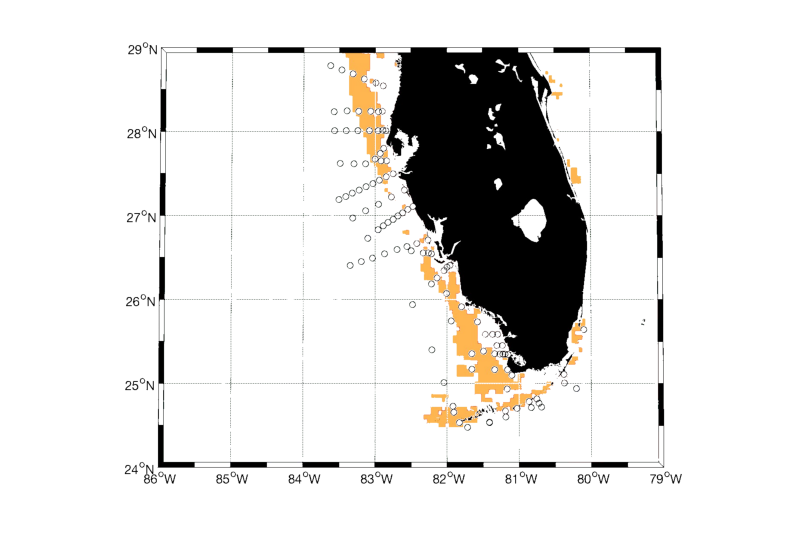

In [14]:
import cv2
import numpy as np

# Load the map image
img = cv2.imread('seascape_for_isolation.jpg')
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# Define color range for Black (landmass)
lower_black = np.array([0, 0, 0])
upper_black = np.array([180, 255, 30])
mask_black = cv2.inRange(hsv, lower_black, upper_black)

# # Define color range for 

# Warm Blooms
lower_selected = np.array([10, 140, 180]) 
upper_selected = np.array([25, 255, 255])
mask_selected = cv2.inRange(hsv, lower_selected, upper_selected)

# # Tropical Seas
# lower_selected = np.array([70, 80, 100]) 
# upper_selected = np.array([95, 255, 220])
# mask_selected = cv2.inRange(hsv, lower_selected, upper_selected)

# Hypersaline Eutrophic
# lower_selected = np.array([0, 130, 170])
# upper_selected = np.array([12, 220, 235])
# mask_selected = cv2.inRange(hsv, lower_selected, upper_selected)

# Combine black and orange masks
combined_mask = cv2.bitwise_or(mask_black, mask_selected)

# Create a solid white background
output = np.full_like(img, 255)

# Copy the black and orange regions onto the white background
output[combined_mask > 0] = img[combined_mask > 0]

import matplotlib.pyplot as plt

# Convert BGR (OpenCV) to RGB (Matplotlib)
output_rgb = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)

# Display in Jupyter
plt.figure(figsize=(10, 8))
plt.imshow(output_rgb)
plt.axis('off')  # Turn off coordinate axes if desired
plt.show()